# FBX Parser

The current FBX Parser is able to:
- Read the skeletal data and print out the skeleton hierarchy.
- Extract animation data and stored as a Pandas dataframe.
- Display metadata, properties (node names, types, children, parents) and offsets information.

Pre-requisite:
- PyMo library - commit: fdb93e644f7df014fbed2bbffa6c88adbda4afcf
- mocolib - commit: c818e9743cdedc7ab9098dd83ff3c5ac8e686dc7

In [1]:
#%matplotlib inline
%matplotlib notebook
#%load_ext autoreload
#%autoreload 2

import fbx
from FbxCommon import *
import numpy as np
import pandas as pd
import pymo
from pymo.viz_tools import *
from pymo.preprocessing import *

import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.pipeline import Pipeline
import pickle

from pymo.data import Joint, MocapData

In [3]:
class FBX_Class(object):

    def __init__(self, filename):
        self.filename = filename  
        self.scene = None
        self.manager = None
        
        self.manager = fbx.FbxManager.Create()
        self.importer = fbx.FbxImporter.Create(self.manager, '')
        self.status = self.importer.Initialize(self.filename)
        
        if not self.status:
            raise IOError()
            
        self.scene = fbx.FbxScene.Create(self.manager, '')
        self.importer.Import(self.scene)
        
        self.root_node = self.get_root_node()
        self.root_name = 'pelvis' #'pelvis' for PXR, 'Hips' for CMU
        self.scene_nodes = self.get_all_nodes()
        self.skeleton_root = None
        self.data = MocapData()
    
    def parse(self):
        skeleton_hierarchy, channel_name = self.parse_skeleton()
        self.data.skeleton = skeleton_hierarchy
        self.data.channel_names = channel_name
        anim_data = self.get_animation()
        
        #for animation file with time as index
        #self.data.values = anim_data
        
        #for PXR skeleton base pose without time information (time is 0)
        self.data.values = self.create_base_pose()
        self.data.root_name = self.skeleton_root
        self.data.framerate = self.get_frame_rate()
        all_nodes = self.get_all_nodes()     
        
        #remove parent of root node (pelvis or Hips)
        #root node should be the joint with XYZ position values
        parent_name = None
        for node in all_nodes:
            for i in range(0, node.GetChildCount()):
                root_child = node.GetChild(i)
                root_child_name = str(root_child.GetName())
                if root_child_name == self.skeleton_root:
                    #print(root_child_name)
                    parent_node = node
                    parent_name = str(node.GetName())
            if parent_name in self.data.channel_names:             
                self.data.channel_names.remove(parent_name)   
        
        #remove unnecessary nodes whose parent is not root(pelvis or Hips)
        #unnecessary nodes can also be deleted in Motion Builder directly
        '''
        self.remove_name_list = []
        self.remove_node_list = []
        for j in range(0, parent_node.GetChildCount()):
            remove_child = parent_node.GetChild(j)
            remove_name = str(remove_child.GetName())
            if remove_name != self.skeleton_root:
                self.remove_name_list.append(remove_name)
                self.remove_node_list.append(remove_child)
                if remove_child.GetChildCount() > 0:
                    self.remove_node(remove_child)
                    
        self.remove_name_list = list(set(self.remove_name_list))
        self.remove_node_list = list(set(self.remove_node_list))
        print(self.remove_name_list)
        print(self.remove_node_list)
        
        for x in self.remove_name_list:
            self.data.channel_names.remove(x)   
        '''
        return self.data
        
    def remove_node(self, node):
        self.remove_name_list.append(str(node.GetName()))
        self.remove_node_list.append(node)
        for i in range(0, node.GetChildCount()):
            self.child = node.GetChild(i)
            self.remove_node(self.child)
    
    
    def get_root_node(self):
        self.root_node = self.scene.GetRootNode()
        return self.root_node
    
    def get_scene_nodes(self, node):
        self.scene_nodes.append(node)
        for i in range(0, node.GetChildCount()):
            self.child = node.GetChild(i)
            self.get_scene_nodes(self.child)
            
    def get_all_nodes(self):
        self.scene_nodes = []
        for i in range(0, self.root_node.GetChildCount()):
            self.get_scene_nodes(self.root_node.GetChild(i))
        return self.scene_nodes
    
    def get_property(self, node, property_string):
        node_property = node.FindProperty(property_string)
        return node_property
    
    '''Display meta data of the FBX scene'''
    def display_scene_info(self):
        scene_info = self.scene.GetSceneInfo()
        if scene_info:
            print("\n--------------------\nMeta-Data\n--------------------\n")
            print("Title: %s" % scene_info.mTitle.Buffer())
            print("Subject: %s" % scene_info.mSubject.Buffer())
            print("Author: %s" % scene_info.mAuthor.Buffer())
            print("Keywords: %s" % scene_info.mKeywords.Buffer())
            print("Revision: %s" % scene_info.mRevision.Buffer())
            print("Comment: %s" % scene_info.mComment.Buffer())
    
    
    '''Display node properties: names, node types, node parents, number of children'''
    def display_node(self, node):
        classid = node.GetClassId()
        print(classid)
        single_node = node.GetNodeAttribute()
        node_class = str(single_node.__class__)[8:]
        node_class = node_class.replace("'", "")
        node_class = node_class.replace(">", "")
        print("Node Class: " + node_class)
        
        if node_class == 'fbx.FbxMarker':
            print("Marker Name: " + node.GetName())
            self.display_marker(single_node)
        elif node_class == 'fbx.FbxSkeleton':
            print("Skeleton Name: " + node.GetName())
            print("Parent: " + node.GetParent().GetName())
            print("Child: " + str(node.GetChildCount()))
            for i in range(0, node.GetChildCount()):
                print(node.GetChild(i).GetName())
            self.display_skeleton(single_node)
        elif node_class == 'fbx.FbxMesh':
            print("Mesh Name: " + node.GetName())
        else:
            print("Node Name: " + node.GetName())
        print("--------------------")
        
    def display_marker(self, marker):
        marker_type = "Marker Type: "
        if marker.GetType() == fbx.FbxMarker.eStandard:
            marker_type += "Standard"
        elif marker.GetType() == fbx.FbxMarker.eOptical:
            marker_type += "Optical"
        elif marker.GetType() == fbx.FbxMarker.eEffectorIK:
            marker_type += "IK Effectorl"
        elif marker.GetType() == fbx.FbxMarker.eEffectorFK:
            marker_type += "FK Effector"
        print(marker_type)
        
    def display_skeleton(self, skeleton):
        types = ["Root", "Limb", "Limb Node", "Effector"]
        skeleton_type_index = skeleton.GetSkeletonType()
        print("Skeleton Type: " + types[skeleton_type_index])
        
        if skeleton.GetSkeletonType() == fbx.FbxSkeleton.eLimb:
            print("Limb Length: " + str(skeleton.LimbLength.Get()))
        elif skeleton.GetSkeletonType() == fbx.FbxSkeleton.eLimbNode:
            print("Limb Node Size: " + str(skeleton.Size.Get()))
        elif skeleton.GetSkeletonType() == fbx.FbxSkeleton.eRoot:
            print("Limb Root Size: " + str(skeleton.Size.Get()))
            
            
    '''
    Display the default translation, rotation and other related properties of each node.
    
    The value of LclTranslation/LclRotation is an offset from the corresponding default TR property vector for the parent node. 
    A node’s default TR properties are therefore local to the parent node.
    The value of scaling vector is 1 in CMU/PXR cases, thus there is no need to consider scaling values.
    '''
    def get_offset(self):  
        all_nodes = self.get_all_nodes()
        anim_stack = self.scene.GetSrcObject(FbxCriteria.ObjectType(FbxAnimStack.ClassId))
        anim_layer = anim_stack.GetSrcObject(FbxCriteria.ObjectType(FbxAnimLayer.ClassId))
        isSwitcher = False        
        timeSpan  = anim_stack.GetLocalTimeSpan()
        time = timeSpan.GetStart()
        for node in all_nodes:
            lPivotState = node.GetPivotState(fbx.FbxNode.eSourcePivot)
            if lPivotState == fbx.FbxNode.ePivotActive:
                print("Pivot State: Active")
            else:
                print("Piv ot State: Reference")
            print(node.GetName())
            
            '''
            In euler angle, the order of rotation axis is very important in a later step to calculate the rotation matrices,
            Thus, it's necessary to check rotation order for each single node. For PRX skeleton, rotation order is Euler XYZ
            '''
            rotation_order = node.GetRotationOrder(FbxNode.eSourcePivot)
            if rotation_order == eEulerXYZ:
                print("Euler XYZ")
            elif rotation_order == eEulerXZY:
                print("Euler XZY")
            elif rotation_order == eEulerYZX:
                print("Euler YZX")
            elif rotation_order == eEulerYXZ:
                print("Euler YXZ")
            elif rotation_order == eEulerZXY:
                print("Euler ZXY")
            elif rotation_order == eEulerZYX:
                print("Euler ZYX")
            elif rotation_order == eSphericXYZ:
                print("Spheric XYZ")

            pre_rotation = node.GetPreRotation(FbxNode.eSourcePivot)
            post_rotation = node.GetPostRotation(FbxNode.eSourcePivot)
            rotation_pivot = node.GetRotationPivot(FbxNode.eSourcePivot)
            rotation_offset = node.GetRotationOffset(FbxNode.eSourcePivot) 
            geo_rotation = node.GetGeometricRotation(FbxNode.eSourcePivot)
            
            rotation_min_x = node.RotationMin.Get()[0]
            rotation_min_y = node.RotationMin.Get()[1]
            rotation_min_z = node.RotationMin.Get()[2]
            rotation_min = [rotation_min_x, rotation_min_y, rotation_min_z]
            
            rotation_max_x = node.RotationMax.Get()[0]
            rotation_max_y = node.RotationMax.Get()[1]
            rotation_max_z = node.RotationMax.Get()[2]
            rotation_max = [rotation_max_x, rotation_max_y, rotation_max_z]
            
            offset_x = node.LclTranslation.Get()[0]
            offset_y = node.LclTranslation.Get()[1]
            offset_z = node.LclTranslation.Get()[2]
            
            rotation_x = node.LclRotation.Get()[0]
            rotation_y = node.LclRotation.Get()[1]
            rotation_z = node.LclRotation.Get()[2]
            
            offset = [offset_x, offset_y, offset_z]
            offset_r = [rotation_x, rotation_y, rotation_z]
            print("local translation", offset)
            print("local rotation", offset_r)
            print("pre rotation", pre_rotation)
            print("post rotation", post_rotation)
            print("rotation pivot", rotation_pivot)
            print("rotation offset", rotation_offset)
            print("rotation min", rotation_min)
            print("rotation max", rotation_max)
            print("geo rotation", geo_rotation)
            
    
    '''
    Get the name, default translation, rotation values of each node in order to recreate the base pose for PXR skeleton
    Bug need to be fixed: some node positions (for example clavicle, wing, weapon, etc.) of the skeleton are incorrect
    '''
    def base_pose_data(self):
        column_names = []
        anim_values = []
        all_nodes = self.get_all_nodes()
        types = ["Root", "Limb", "Limb Node", "Effector"]
        for node in all_nodes:
            attribute = node.GetNodeAttribute()
            node_class = str(attribute.__class__)[8:]
            node_class = node_class.replace("'", "")
            node_class = node_class.replace(">", "")
            if node_class == 'fbx.FbxSkeleton':   
                node_name = str(node.GetName())
                skeleton_type_index = attribute.GetSkeletonType()
                skeleton_type = types[skeleton_type_index]
                #if skeleton_type == "Root"
                if node_name == self.root_name:   #Hips for CMU, pelvis for PXR
                    translation_x = node.LclTranslation.Get()[0]
                    channel_TX = "Xposition"
                    column_TX = '%s_%s'%(node_name, channel_TX)
                    column_names.append(column_TX)
                    anim_values.append(translation_x)
                    
                    translation_y = node.LclTranslation.Get()[1]
                    channel_TY = "Yposition"
                    column_TY = '%s_%s'%(node_name, channel_TY)
                    column_names.append(column_TY)
                    anim_values.append(translation_y)
                    
                    translation_z = node.LclTranslation.Get()[2]
                    channel_TZ = "Zposition"
                    column_TZ = '%s_%s'%(node_name, channel_TZ)
                    column_names.append(column_TZ)
                    anim_values.append(translation_z)
                
                rotation_x = node.LclRotation.Get()[0]
                pre_rotation_x = node.GetPreRotation(FbxNode.eSourcePivot)[0]
                if node_name == self.root_name: #Hips or pelvis
                    rotation_x = node.LclRotation.Get()[0] + 90 #90 degree is added to rotate the root to correct position
                if node_name == 'weapon_r':
                    rotation_x = -node.LclRotation.Get()[0] 
                #if node_name == 'wingroot_bott_base_r':
                #    rotation_x = -node.LclRotation.Get()[0] 
                rotation_x = rotation_x - pre_rotation_x
                channel_RX = "Xrotation"
                column_RX = '%s_%s'%(node_name, channel_RX)
                column_names.append(column_RX)
                anim_values.append(rotation_x)
                
                rotation_y = node.LclRotation.Get()[1] 
                pre_rotation_y = node.GetPreRotation(FbxNode.eSourcePivot)[1]
                if node_name == 'clavicle_r':
                    rotation_y = -node.LclRotation.Get()[1] 
                rotation_y = rotation_y - pre_rotation_y       
                channel_RY = "Yrotation"
                column_RY = '%s_%s'%(node_name, channel_RY)
                column_names.append(column_RY)
                anim_values.append(rotation_y)
            
                rotation_z = node.LclRotation.Get()[2]
                pre_rotation_z = node.GetPreRotation(FbxNode.eSourcePivot)[2]
                if node_name == 'wingroot_bott_base_l':
                    rotation_z = -node.LclRotation.Get()[2]
                rotation_z = rotation_z - pre_rotation_z   
                channel_RZ = "Zrotation"
                column_RZ = '%s_%s'%(node_name, channel_RZ)
                column_names.append(column_RZ)
                anim_values.append(rotation_z)          
        return anim_values, column_names

    def create_base_pose(self):
        anim_values, column_names = self.base_pose_data()
        time_zero = pd.to_timedelta(0, unit='s')
        df = pd.DataFrame(anim_values, columns=[time_zero], index=column_names)
        df = df.transpose()
        return df

    
    '''
    Extract the animation data from a scene.
    
    An FBX scene can contain one or more animation stacks. 
    The animation stack is the highest level container for animation data. 
    An animation stack is equivalent to one take of animation.
    An animation stack contains one or more animation layers. 
    An animation layer contains one or more animation curve nodes.
    
    We can retrieve the animation curves for node properties such as the local translation/rotation of a node (or a layer), 
    and then store the data in a pandas dataframe
    '''    
    def get_animation(self):
        for i in range(self.scene.GetSrcObjectCount(FbxCriteria.ObjectType(FbxAnimStack.ClassId))):
            AnimStack = self.scene.GetSrcObject(FbxCriteria.ObjectType(FbxAnimStack.ClassId), i)
            animation = self.get_animation_stack(AnimStack, self.scene.GetRootNode(), False)
        return animation
       
    def get_animation_stack(self, anim_stack, node, isSwitcher):
        anim_layers = anim_stack.GetSrcObjectCount(FbxCriteria.ObjectType(FbxAnimLayer.ClassId))   
        for i in range(anim_layers):
            i_anim_layer = anim_stack.GetSrcObject(FbxCriteria.ObjectType(FbxAnimLayer.ClassId), i)
            anim_stack = self.get_all_animation_layer(i_anim_layer, node, isSwitcher)        
        return anim_stack    
    
    def get_animation_layer(self, anim_layer, node, isSwitcher=False):
        node_name = str(node.GetName())        
        channel_anim, channel_name = self.get_channels(node, anim_layer, isSwitcher)
        column_names = ['%s_%s'%(node_name, c) for c in channel_name]
        df = pd.DataFrame()
        if len(channel_anim) > 0:
            time_lst = channel_anim[0]
            time_delta = pd.to_timedelta([a[0] for a in time_lst], unit='s')
            
            anim_lst = []
            for i in range(len(channel_anim)):#3
                single_anim = channel_anim[i]
                single_anim_lst = [a[1] for a in single_anim] 
                anim_lst.append(single_anim_lst)
            df = pd.DataFrame(data=anim_lst, index=column_names, columns=time_delta)
            df = df.transpose()     
        return df
    
    def get_all_animation_layer(self, anim_layer, node, isSwitcher=False):
        all_nodes = self.get_all_nodes()
        all_anim = []
        for node in all_nodes:
            anim_data = self.get_animation_layer(anim_layer, node, isSwitcher)
            all_anim.append(anim_data)
        all_anim = pd.concat(all_anim, axis=1)
        return all_anim   
                    
    def get_channels(self, node, anim_layer, isSwitcher):
        lAnimCurve = None
        KFCURVENODE_T_X = "X"
        KFCURVENODE_T_Y = "Y"
        KFCURVENODE_T_Z = "Z"

        KFCURVENODE_R_X = "X"
        KFCURVENODE_R_Y = "Y"
        KFCURVENODE_R_Z = "Z"
        KFCURVENODE_R_W = "W"
        
        channel_motions = []
        channel_names = []
        if not isSwitcher:
            lAnimCurve = node.LclTranslation.GetCurve(anim_layer, KFCURVENODE_T_X)
            if lAnimCurve:
                '''
                Another method to get root node, works for an animation file
                a root node will be the node with LclTranslation values in all the frames,
                Other nodes only have LclRotation information.
                #root_name = node.GetName()
                #root_name = str(root_name)
                #self.skeleton_root = root_name
                '''
                channel_TX = "Xposition"
                motion_TX = self.get_curve(lAnimCurve)
                channel_motions.append(motion_TX)
                channel_names.append(channel_TX)
            
            #Get translation (position) information
            lAnimCurve = node.LclTranslation.GetCurve(anim_layer, KFCURVENODE_T_Y)
            if lAnimCurve:
                channel_TY = "Yposition"
                motion_TY = self.get_curve(lAnimCurve)
                channel_motions.append(motion_TY)
                channel_names.append(channel_TY)

            lAnimCurve = node.LclTranslation.GetCurve(anim_layer, KFCURVENODE_T_Z)
            if lAnimCurve:
                channel_TZ = "Zposition"
                motion_TZ = self.get_curve(lAnimCurve)
                channel_motions.append(motion_TZ)
                channel_names.append(channel_TZ)
                
            #Get rotation information
            lAnimCurve = node.LclRotation.GetCurve(anim_layer, KFCURVENODE_R_X)
            if lAnimCurve:
                channel_RX = "Xrotation"
                motion_RX = self.get_curve(lAnimCurve)
                channel_motions.append(motion_RX)
                channel_names.append(channel_RX)

            lAnimCurve = node.LclRotation.GetCurve(anim_layer, KFCURVENODE_R_Y)
            if lAnimCurve:
                channel_RY = "Yrotation"
                motion_RY = self.get_curve(lAnimCurve)
                channel_motions.append(motion_RY)
                channel_names.append(channel_RY)

            lAnimCurve = node.LclRotation.GetCurve(anim_layer, KFCURVENODE_R_Z)
            if lAnimCurve:
                channel_RZ = "Zrotation"
                motion_RZ =self.get_curve(lAnimCurve)
                channel_motions.append(motion_RZ)
                channel_names.append(channel_RZ)
             
        return channel_motions, channel_names
        
        '''
        #scaling is not required for CMU or PXR skeletons
            lAnimCurve = node.LclScaling.GetCurve(anim_layer, KFCURVENODE_S_X)
            if lAnimCurve:
                print("Local Scaling_X")
                self.get_curve(lAnimCurve)

            lAnimCurve = node.LclScaling.GetCurve(anim_layer, KFCURVENODE_S_Y)
            if lAnimCurve:
                print("Local Scaling_Y")
                self.get_curve(lAnimCurve)

            lAnimCurve = node.LclScaling.GetCurve(anim_layer, KFCURVENODE_S_Z)
            if lAnimCurve:
                print("Local Scaling_Z")
                self.get_curve(lAnimCurve)
        '''
                
    def get_curve(self, pCurve):
        frame_time = 0.0
        frame_rate = self.get_frame_rate()
        frame_count = pCurve.KeyGetCount()
        motions = [()] * frame_count
        for i in range(frame_count):
            key_value = pCurve.KeyGetValue(i)
            key_time  = pCurve.KeyGetTime(i) #time at which this key is occurring
            motions[i] = (frame_time, key_value)
            frame_time = frame_time + frame_rate
        return motions     
           
        
    def get_start_and_end_frames(self):
        ''' Timeline default timespan '''
        lGlobalSettings = self.scene.GetGlobalSettings()
        lTs = lGlobalSettings.GetTimelineDefaultTimeSpan()
        lStart = lTs.GetStart()
        lEnd   = lTs.GetStop()
        print(lStart)
        startFrame = int(lStart.GetTimeString('', 10))
        endFrame = int(lEnd.GetTimeString('', 10))
        return startFrame, endFrame
    
    '''Get frame rate of the scene'''
    def get_frame_rate(self):
        lTimeModes = [ "Default Mode", "Cinema", "PAL", "Frames 30", 
                        "NTSC Drop Frame", "Frames 50", "Frames 60",
                        "Frames 100", "Frames 120", "NTSC Full Frame", 
                        "Frames 30 Drop", "Frames 1000" ] 
        timeModesCount = fbx.FbxTime.eModesCount
        lGlobalSettings = self.scene.GetGlobalSettings()
        lTimeModeIdx = lGlobalSettings.GetTimeMode()
        lFps = fbx.FbxTime.GetFrameRate(lTimeModeIdx)
        lFps = 1/lFps
        return lFps
    
    def new_bone(self, node):
        parent = node.GetParent().GetName()
        parent = str(parent)#[14:] #Remove cameronFraser
        if "End" in parent:
            parent = parent.replace("End", "Nub")
        children = []
        for i in range(0, node.GetChildCount()):
            child_node = node.GetChild(i)
            child = str(child_node.GetName()) #[14:] #Remove cameronFraser
            #for CMU files, a node has the key word 'End' if it is an end site
            if "End" in child:
                child = child.replace("End", "Nub")
            children.append(child)
        bone = {'parent': parent, 'children': children}
        return bone
    
    def parse_skeleton(self):
        skeleton = {}
        skeleton_root = None
        root_bone = None
        root_name = None
        all_nodes = self.get_all_nodes()
        types = ["Root", "Limb", "Limb Node", "Effector"]
        node_lst = []
        channel_name = []
        for node in all_nodes:
            attribute = node.GetNodeAttribute()
            node_class = str(attribute.__class__)[8:]
            node_class = node_class.replace("'", "")
            node_class = node_class.replace(">", "")
            if node_class == 'fbx.FbxSkeleton':
                root_name = node.GetName()
                root_name = str(root_name)#[14:] #Remove cameronFraser  
                #CMU
                if "End" in root_name:
                    root_name = root_name.replace("End", "Nub") 
                    
                root_bone = self.new_bone(node)
                offset_x = node.LclTranslation.Get()[0]
                offset_y = node.LclTranslation.Get()[1]
                offset_z = node.LclTranslation.Get()[2]
                
                offset = [offset_x, offset_y, offset_z]
                root_bone['offsets'] = offset
                root_bone['channels'] = ['Xrotation', 'Yrotation', 'Zrotation']
                
                skeleton_type_index = attribute.GetSkeletonType()
                skeleton_type = types[skeleton_type_index]
                node_lst.append(str(node.GetName()))
                
                #if skeleton_type == "Root":
                if str(node.GetName()) == self.root_name: #Hips or pelvis 
                    skeleton_root = node.GetName()
                    self.skeleton_root = str(skeleton_root)#[14:] #Remove cameronFraser 
                
                #For CMU file, append channel_name if the node is not an end node
                #For PXR, we keep the channel_name as all nodes need to be shown in the visualization result 
                if "Nub" not in root_name:
                    channel_name.append(root_name)
                #Rotation channels (XYZ) is empty if the node is an end node
                else:
                    root_bone['channels'] = []
                            
            skeleton[root_name] = root_bone                     
        return skeleton, channel_name
    


In [4]:
#filepath = ('C:/Users/zhuoc/mocolib/data/cmu/fbx/Performance_tk01.fbx')
#filepath = ('C:/Users/zhuoc/mocolib/data/cmu/fbx/10_02.fbx')

#filepath = ('C:/Users/zhuoc/mocolib/data/cmu/fbx/Performance_tk01_animation.fbx')
#filepath = ('C:/Users/zhuoc/mocolib/data/cmu/fbx/Wukong-Cameron-2.fbx')
filepath = ('C:/Users/zhuoc/mocolib/data/cmu/fbx/Fey-Sidonie-2.fbx')
#filepath = ('C:/Users/zhuoc/mocolib/data/cmu/fbx/Zinx-Kasha-3.fbx')

fbx_scene = FBX_Class(filepath)
fbx_scene.display_scene_info()

data = [fbx_scene.parse()]
#data = fbx_scene.parse()

#print(data.root_name)
#print(data.skeleton)


--------------------
Meta-Data
--------------------

Title: 
Subject: 
Author: 
Keywords: 
Revision: 
Comment: 


In [39]:
fbx_scene.parse_skeleton()

({'C_brow_mid': {'channels': ['Xrotation', 'Yrotation', 'Zrotation'],
   'children': [],
   'offsets': [0.036125488579273224, -7.680029392242432, 4.7100324630737305],
   'parent': 'faceAttach'},
  'C_jaw': {'channels': ['Xrotation', 'Yrotation', 'Zrotation'],
   'children': ['L_lip_lower_outer',
    'C_lip_lower_mid',
    'R_lip_lower_outer',
    'teeth_lower',
    'tongue'],
   'offsets': [-0.013724635355174541,
    0.058574702590703964,
    -1.6388226747512817],
   'parent': 'faceAttach'},
  'C_lip_lower_mid': {'channels': ['Xrotation', 'Yrotation', 'Zrotation'],
   'children': [],
   'offsets': [0.06185023486614227, -8.192636489868164, -1.0400347709655762],
   'parent': 'C_jaw'},
  'C_lip_upper_mid': {'channels': ['Xrotation', 'Yrotation', 'Zrotation'],
   'children': [],
   'offsets': [0.03929496929049492, -8.44779109954834, -2.048328399658203],
   'parent': 'faceAttach'},
  'C_nose_bridge': {'channels': ['Xrotation', 'Yrotation', 'Zrotation'],
   'children': [],
   'offsets': [0.0

In [5]:
#PXR
fbx_scene.create_base_pose()

,pelvis_Xposition,pelvis_Yposition,pelvis_Zposition,pelvis_Xrotation,pelvis_Yrotation,pelvis_Zrotation,skirt_top_01_Xrotation,skirt_top_01_Yrotation,skirt_top_01_Zrotation,skirt_top_02_Xrotation,...,skirt_bott_12_Zrotation,skirt_bott_13_Xrotation,skirt_bott_13_Yrotation,skirt_bott_13_Zrotation,skirt_bott_14_Xrotation,skirt_bott_14_Yrotation,skirt_bott_14_Zrotation,thigh_twist_02_r_Xrotation,thigh_twist_02_r_Yrotation,thigh_twist_02_r_Zrotation
0 days,1.023857e-14,-0.800543,98.096558,179.998116,-89.790634,-89.998116,90.0,70.830475,90.208275,100.060509,...,78.744736,-99.919273,69.605957,87.82328,-79.587318,83.547417,106.341843,-7.454425e-17,1.192708e-15,-4.373263e-15


In [6]:
#CMU
fbx_scene.create_base_pose()

,Hips_Xposition,Hips_Yposition,Hips_Zposition,Hips_Xrotation,Hips_Yrotation,Hips_Zrotation,LHipJoint_Xrotation,LHipJoint_Yrotation,LHipJoint_Zrotation,LeftUpLeg_Xrotation,...,RightHandIndex1_Zrotation,RightHandIndex1_End_Xrotation,RightHandIndex1_End_Yrotation,RightHandIndex1_End_Zrotation,RThumb_Xrotation,RThumb_Yrotation,RThumb_Zrotation,RThumb_End_Xrotation,RThumb_End_Yrotation,RThumb_End_Zrotation
0 days,10.4674,18.295401,-18.191401,0.0,0.0,0.0,-10.600193,20.956718,53.276083,0.0,...,-180.0,0.0,0.0,0.0,-180.0,45.0,180.0,0.0,0.0,0.0


In [7]:
#CMU
fbx_scene.get_animation()


,Hips_Xposition,Hips_Yposition,Hips_Zposition,Hips_Xrotation,Hips_Yrotation,Hips_Zrotation,LHipJoint_Xrotation,LHipJoint_Yrotation,LHipJoint_Zrotation,LeftUpLeg_Xrotation,...,RightHand_Zrotation,RightFingerBase_Xrotation,RightFingerBase_Yrotation,RightFingerBase_Zrotation,RightHandIndex1_Xrotation,RightHandIndex1_Yrotation,RightHandIndex1_Zrotation,RThumb_Xrotation,RThumb_Yrotation,RThumb_Zrotation
00:00:00,10.4674,18.295401,-18.191401,0.0000,0.000000,0.0000,0.0,0.0,0.0,0.0000,...,0.0,0.0000,0.000000,0.0000,0.0,0.0,0.000,0.0000,0.0000,0.0000
00:00:00.008333,10.4674,17.770000,-18.191401,7.7033,-37.371498,-8.4567,0.0,0.0,0.0,-12.2205,...,0.0,-3.0855,16.239000,-10.9104,0.0,0.0,7.125,8.4269,-13.6828,11.2368
00:00:00.016666,10.4675,17.768600,-18.194401,7.7532,-37.275902,-8.6228,0.0,0.0,0.0,-12.2510,...,0.0,-3.1488,16.186199,-11.1636,0.0,0.0,7.125,8.2883,-13.7158,11.0692
00:00:00.025000,10.4649,17.764400,-18.173100,7.2412,-37.389801,-8.0305,0.0,0.0,0.0,-11.8844,...,0.0,-3.1428,15.974400,-11.2832,0.0,0.0,7.125,8.1802,-13.9175,10.9917
00:00:00.033333,10.4623,17.764900,-18.170401,7.1881,-37.499298,-7.9296,0.0,0.0,0.0,-11.7566,...,0.0,-3.0821,15.922500,-11.1043,0.0,0.0,7.125,8.2571,-13.9829,11.1114
00:00:00.041666,10.4599,17.764400,-18.170401,7.2069,-37.598999,-7.9140,0.0,0.0,0.0,-11.7117,...,0.0,-3.1136,16.069599,-11.1177,0.0,0.0,7.125,8.2843,-13.8355,11.1009
00:00:00.050000,10.4586,17.763500,-18.168900,7.3317,-37.621498,-8.0653,0.0,0.0,0.0,-11.7570,...,0.0,-3.1961,16.065399,-11.4083,0.0,0.0,7.125,8.1387,-13.8171,10.9076
00:00:00.058333,10.4578,17.764700,-18.167999,7.5209,-37.598701,-8.2989,0.0,0.0,0.0,-11.8234,...,0.0,-3.1966,15.784700,-11.6021,0.0,0.0,7.125,7.9790,-14.0821,10.7808
00:00:00.066666,10.4555,17.764500,-18.164700,7.4046,-37.635101,-8.1228,0.0,0.0,0.0,-11.8055,...,0.0,-3.1555,15.724000,-11.4986,0.0,0.0,7.125,8.0165,-14.1505,10.8506
00:00:00.075000,10.4528,17.762800,-18.159800,7.1814,-37.676498,-7.8629,0.0,0.0,0.0,-11.7000,...,0.0,-3.1440,16.014000,-11.2607,0.0,0.0,7.125,8.2004,-13.8798,11.0063


In [8]:
#CMU
print(data[0].values.head(10))

                 Hips_Xposition  Hips_Yposition  Hips_Zposition  \
00:00:00                10.4674       18.295401      -18.191401   
00:00:00.008333         10.4674       17.770000      -18.191401   
00:00:00.016666         10.4675       17.768600      -18.194401   
00:00:00.025000         10.4649       17.764400      -18.173100   
00:00:00.033333         10.4623       17.764900      -18.170401   
00:00:00.041666         10.4599       17.764400      -18.170401   
00:00:00.050000         10.4586       17.763500      -18.168900   
00:00:00.058333         10.4578       17.764700      -18.167999   
00:00:00.066666         10.4555       17.764500      -18.164700   
00:00:00.075000         10.4528       17.762800      -18.159800   

                 Hips_Xrotation  Hips_Yrotation  Hips_Zrotation  \
00:00:00                 0.0000        0.000000          0.0000   
00:00:00.008333          7.7033      -37.371498         -8.4567   
00:00:00.016666          7.7532      -37.275902         -8.62

In [9]:
fbx_scene.get_frame_rate() 

0.008333333333333333

In [10]:
fbx_scene.get_root_node()

In [6]:
#PXR
print((data[0].channel_names))

['pelvis', 'skirt_top_01', 'skirt_top_02', 'skirt_top_03', 'skirt_top_04', 'skirt_top_05', 'skirt_top_06', 'skirt_top_07', 'skirt_top_08', 'skirt_top_09', 'skirt_top_10', 'skirt_top_11', 'skirt_top_12', 'skirt_top_13', 'skirt_top_14', 'spine_01', 'spine_02', 'spine_03', 'breast_l', 'breast_r', 'clavicle_l', 'upperarm_l', 'lowerarm_l', 'hand_l', 'index_01_l', 'index_02_l', 'index_03_l', 'middle_01_l', 'middle_02_l', 'middle_03_l', 'pinky_01_l', 'pinky_02_l', 'pinky_03_l', 'ring_01_l', 'ring_02_l', 'ring_03_l', 'thumb_01_l', 'thumb_02_l', 'thumb_03_l', 'weapon_l', 'lowerarm_twist_01_l', 'lowerarm_twist_02_l', 'clavicle_r', 'upperarm_r', 'lowerarm_r', 'hand_r', 'index_01_r', 'index_02_r', 'index_03_r', 'middle_01_r', 'middle_02_r', 'middle_03_r', 'pinky_01_r', 'pinky_02_r', 'pinky_03_r', 'ring_01_r', 'ring_02_r', 'ring_03_r', 'thumb_01_r', 'thumb_02_r', 'thumb_03_r', 'weapon_r', 'seed_open', 'seed_sprout_01', 'seed_sprout_02', 'seed_sprout_03', 'lowerarm_twist_01_r', 'lowerarm_twist_02_r'

In [11]:
#CMU
print((data[0].channel_names))

['Hips', 'LHipJoint', 'LeftUpLeg', 'LeftLeg', 'LeftFoot', 'LeftToeBase', 'RHipJoint', 'RightUpLeg', 'RightLeg', 'RightFoot', 'RightToeBase', 'LowerBack', 'Spine', 'Spine1', 'Neck', 'Neck1', 'Head', 'LeftShoulder', 'LeftArm', 'LeftForeArm', 'LeftHand', 'LeftFingerBase', 'LeftHandIndex1', 'LThumb', 'RightShoulder', 'RightArm', 'RightForeArm', 'RightHand', 'RightFingerBase', 'RightHandIndex1', 'RThumb']


In [7]:
print(data[0].root_name)


pelvis


In [8]:
print((data[0].values))

        pelvis_Xposition  pelvis_Yposition  pelvis_Zposition  \
0 days      1.023857e-14         -0.800543         98.096558   

        pelvis_Xrotation  pelvis_Yrotation  pelvis_Zrotation  \
0 days        179.998116        -89.790634        -89.998116   

        skirt_top_01_Xrotation  skirt_top_01_Yrotation  \
0 days                    90.0               70.830475   

        skirt_top_01_Zrotation  skirt_top_02_Xrotation  ...  \
0 days               90.208275              100.060509  ...   

        skirt_bott_12_Zrotation  skirt_bott_13_Xrotation  \
0 days                78.744736               -99.919273   

        skirt_bott_13_Yrotation  skirt_bott_13_Zrotation  \
0 days                69.605957                 87.82328   

        skirt_bott_14_Xrotation  skirt_bott_14_Yrotation  \
0 days               -79.587318                83.547417   

        skirt_bott_14_Zrotation  thigh_twist_02_r_Xrotation  \
0 days               106.341843               -7.454425e-17   

        

In [9]:
#PXR
print_skel(data[0])

- pelvis (RootNode)
| | | | | | | | | | | | | | | | - thigh_r (pelvis)
| | | | | | | | | | | | | | | | | | - thigh_twist_02_r (thigh_r)
| | | | | | | | | | | | | | | | | - thigh_twist_01_r (thigh_r)
| | | | | | | | | | | | | | | | | | | | | | | - skirt_bott_14 (thigh_twist_01_r)
| | | | | | | | | | | | | | | | | | | | | | - skirt_bott_13 (thigh_twist_01_r)
| | | | | | | | | | | | | | | | | | | | | - skirt_bott_12 (thigh_twist_01_r)
| | | | | | | | | | | | | | | | | | | | - skirt_bott_11 (thigh_twist_01_r)
| | | | | | | | | | | | | | | | | | | - skirt_bott_10 (thigh_twist_01_r)
| | | | | | | | | | | | | | | | | | - skirt_bott_09 (thigh_twist_01_r)
| | | | | | | | | | | | | | | | | - skirt_bott_08 (thigh_twist_01_r)
| | | | | | | | | | | | | | | | - calf_r (thigh_r)
| | | | | | | | | | | | | | | | | | - foot_r (calf_r)
| | | | | | | | | | | | | | | | | | - ball_r (foot_r)
| | | | | | | | | | | | | | | | | | | | | | - ring_proximal_phalange_r (ball_r)
| | | | | | | | | | | | | | | | | | |

In [14]:
#CMU
print_skel(data[0])

- Hips (reference)
| | - LowerBack (Hips)
| | - Spine (LowerBack)
| | - Spine1 (Spine)
| | | | - RightShoulder (Spine1)
| | | | - RightArm (RightShoulder)
| | | | - RightForeArm (RightArm)
| | | | - RightHand (RightForeArm)
| | | | | - RThumb (RightHand)
| | | | | - RThumb_Nub (RThumb)
| | | | - RightFingerBase (RightHand)
| | | | - RightHandIndex1 (RightFingerBase)
| | | | - RightHandIndex1_Nub (RightHandIndex1)
| | | - LeftShoulder (Spine1)
| | | - LeftArm (LeftShoulder)
| | | - LeftForeArm (LeftArm)
| | | - LeftHand (LeftForeArm)
| | | | - LThumb (LeftHand)
| | | | - LThumb_Nub (LThumb)
| | | - LeftFingerBase (LeftHand)
| | | - LeftHandIndex1 (LeftFingerBase)
| | | - LeftHandIndex1_Nub (LeftHandIndex1)
| | - Neck (Spine1)
| | - Neck1 (Neck)
| | - Head (Neck1)
| | - Head_Nub (Head)
| - RHipJoint (Hips)
| - RightUpLeg (RHipJoint)
| - RightLeg (RightUpLeg)
| - RightFoot (RightLeg)
| - RightToeBase (RightFoot)
| - RightToeBase_Nub (RightToeBase)
- LHipJoint (Hips)
- LeftUpLeg (LHipJoint

In [10]:
dr_pipe = Pipeline([
    ('param', MocapParameterizer('position')),
])

In [11]:
data[0].values.shape

(1, 486)

In [12]:
xx = dr_pipe.fit_transform(data)

In [13]:
print(xx[0].values.head(10))

        pelvis_Xposition  pelvis_Yposition  pelvis_Zposition  \
0 days      1.023857e-14         -0.800543         98.096558   

        thigh_r_Xposition  thigh_r_Yposition  thigh_r_Zposition  \
0 days          -8.350489          -9.036302          96.078864   

        thigh_twist_02_r_Xposition  thigh_twist_02_r_Yposition  \
0 days                   -8.943975                  -34.705563   

        thigh_twist_02_r_Zposition  thigh_twist_01_r_Xposition  ...  \
0 days                   94.868285                   -8.359583  ...   

        skirt_top_04_Zposition  skirt_top_03_Xposition  \
0 days               97.951441               12.969261   

        skirt_top_03_Yposition  skirt_top_03_Zposition  \
0 days                0.613275              101.919016   

        skirt_top_02_Xposition  skirt_top_02_Yposition  \
0 days                8.385678                -1.88852   

        skirt_top_02_Zposition  skirt_top_01_Xposition  \
0 days              105.868907                3.807

<IPython.core.display.Javascript object>


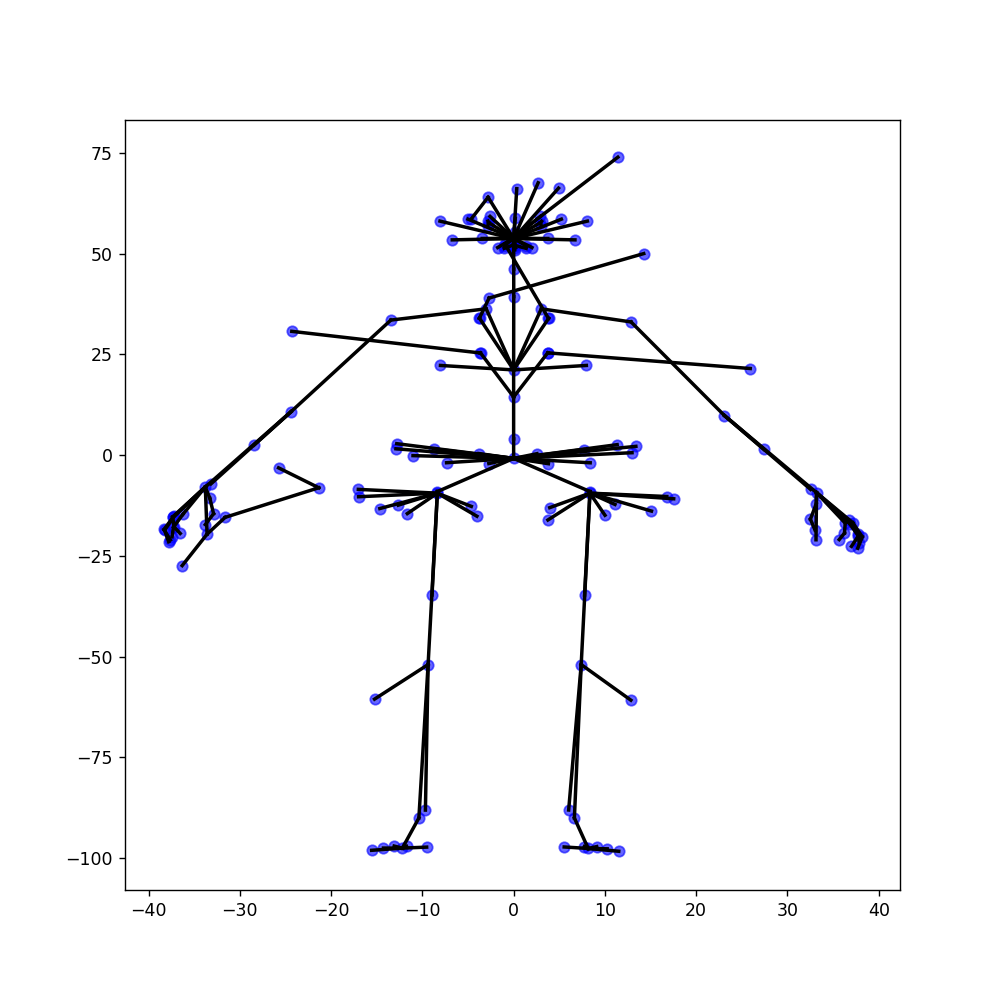

In [14]:
#PXR
draw_stickfigure(xx[0], frame = 0)

<IPython.core.display.Javascript object>


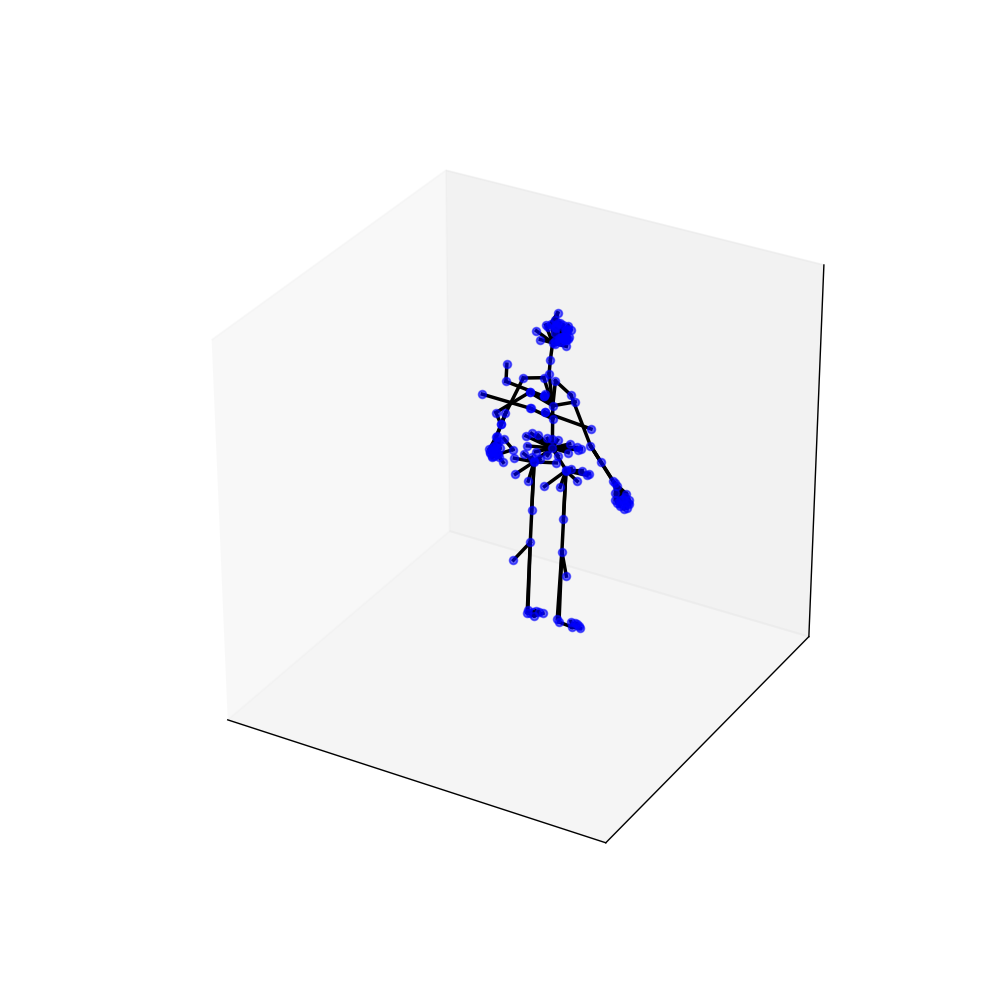

In [15]:
#PXR, 3D 
draw_stickfigure3d(xx[0], frame = 0)

<IPython.core.display.Javascript object>


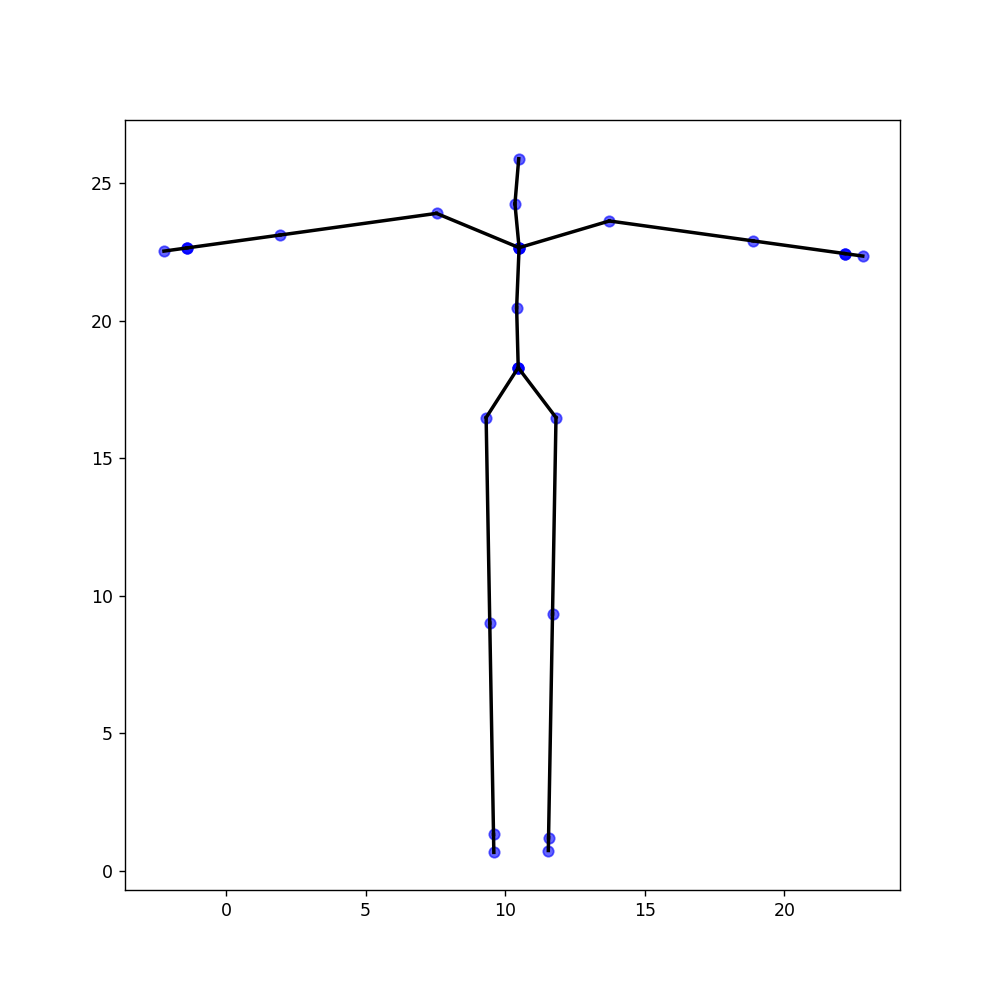

In [19]:
draw_stickfigure(xx[0], frame = 0)

<IPython.core.display.Javascript object>


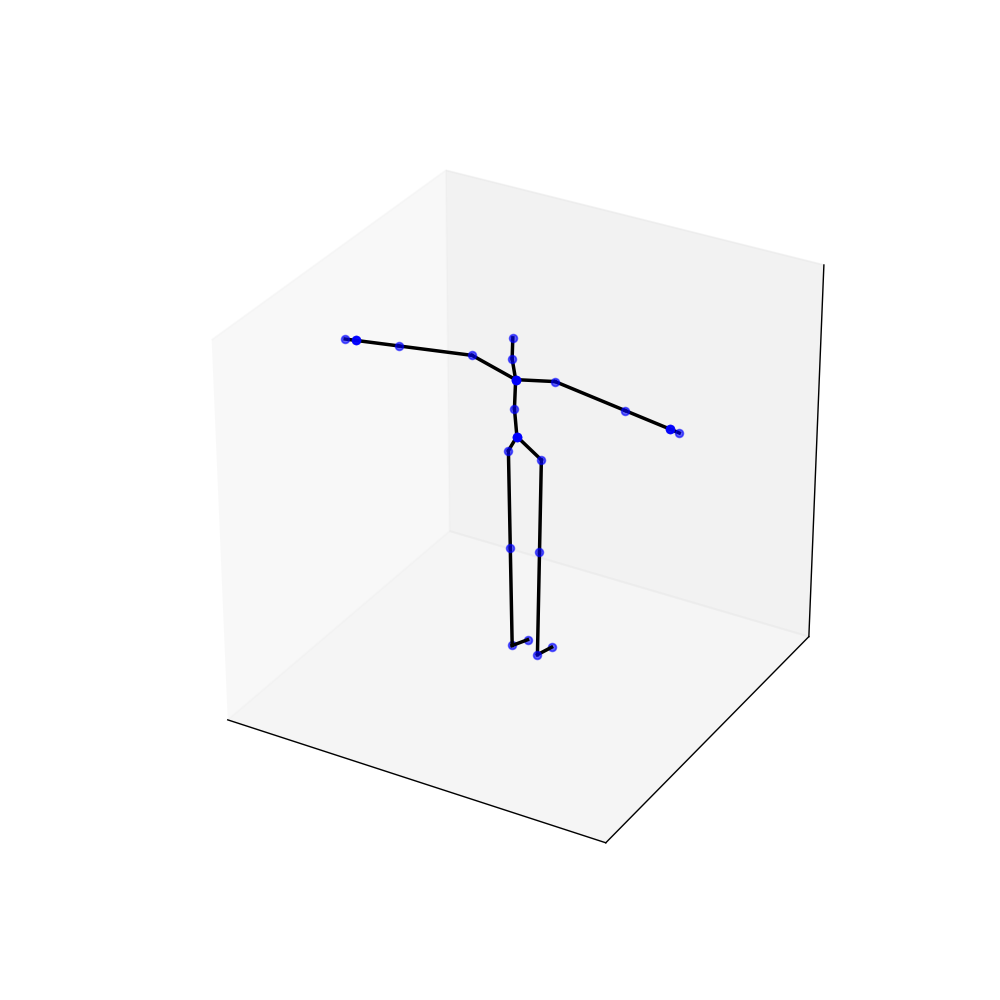

In [20]:
draw_stickfigure3d(xx[0], frame = 0)